# Bonus: building DNA systems for MD

Thor van Heesch (T.vanHeesch@uva.nl) and Jocelyne Vreede (J.Vreede@uva.nl)

van 't Hoff Institute for Molecular Sciences, University of Amsterdam

===

This notebook is for participants who finished `1_analyze.ipynb` and `2_build.ipynb`. It shows more of what mdna can build for MD simulations: DNA bound to proteins, DNA loops, chemical modifications, supercoiled and interlocked DNA.

The sections are independent, so pick the ones you like:

1. **A nucleosome with linker DNA.** Extend the DNA of a crystal structure, and make several starting structures.
2. **Connecting DNA.** Fill the gap between two pieces of DNA, and fold DNA into a loop between proteins.
3. **Modifications your force field may not know.** Methylation, Hoogsteen base pairs and non-canonical bases.
4. **Supercoiled minicircles.** Where does extra linking number go, and an atomistic movie of supercoiling. Takes about 5 minutes to run.
5. **Interlocked DNA rings.** Build a DNA catenane and compute the linking number between two rings.
6. **Before you simulate.** Export for AMBER force fields, overlaps and the size of the water box.

Sections 1 and 2 download a structure from the Protein Data Bank, so they need an internet connection. Each section starts with an example and ends with questions. Run the import cell below first.

In [1]:
# The solutions are in the solutions/ folder: run them from the main folder, where data/ and devtools/ are
import os
if os.path.basename(os.getcwd()) == 'solutions':
    os.chdir('..')

In [2]:
import os
import urllib.request

import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt

import devtools.mdna_workarounds  # fixes for known issues in mdna 0.2.0, see devtools/mdna_workarounds.py
import mdna
from devtools.viewer import view  # 3D viewer inside the notebook, see devtools/viewer.py

os.makedirs('data', exist_ok=True)

## 1. A nucleosome with linker DNA

In the cell, DNA is wrapped around histone proteins. A nucleosome core particle contains 147 bp of DNA wrapped around eight histones. Here you analyse the DNA in the crystal structure 1KX5 (Davey et al., J. Mol. Biol. 2002) with the tools from `1_analyze.ipynb`. Then you add linker DNA on both sides, as in chromatin.

In [3]:
# download the structure from the Protein Data Bank (only the first time)
if not os.path.exists('data/1kx5.pdb'):
    urllib.request.urlretrieve('https://files.rcsb.org/download/1KX5.pdb', 'data/1kx5.pdb')

pdb = md.load('data/1kx5.pdb')
print(pdb)
for chain in pdb.top.chains:
    print(f'chain {chain.index}: {chain.n_residues} residues, first residue {chain.residue(0).name}')

<mdtraj.Trajectory with 1 frames, 16755 atoms, 4416 residues, and unitcells>
chain 0: 147 residues, first residue DA
chain 1: 147 residues, first residue DA
chain 2: 135 residues, first residue ALA
chain 3: 102 residues, first residue SER
chain 4: 128 residues, first residue SER
chain 5: 122 residues, first residue ALA
chain 6: 135 residues, first residue ALA
chain 7: 102 residues, first residue SER
chain 8: 128 residues, first residue SER
chain 9: 122 residues, first residue ALA
chain 10: 7 residues, first residue MN
chain 11: 6 residues, first residue MN
chain 12: 1 residues, first residue CL
chain 13: 1 residues, first residue CL
chain 14: 2 residues, first residue MN
chain 15: 1 residues, first residue CL
chain 16: 780 residues, first residue HOH
chain 17: 802 residues, first residue HOH
chain 18: 219 residues, first residue HOH
chain 19: 129 residues, first residue HOH
chain 20: 214 residues, first residue HOH
chain 21: 196 residues, first residue HOH
chain 22: 221 residues, first

Chains 0 and 1 are the two DNA strands and chains 2 to 9 are the histones. The other chains are ions and water. Load the DNA into mdna:

In [4]:
nucleosome = mdna.load(pdb, chainids=[0, 1])
nucleosome.describe()
view(nucleosome)

DNA structure with 147 base pairs
Sequence: ATCAATATCCACCTGCAGATACTACCAAAAGTGTATTTGGAAACTGCTCCATCAAAAGGCATGTTCAGCTGGAATCCAGCTGAACATGCCTTTTGATGGAGCAGTTTCCAAATACACTTTTGGTAGTATCTGCAGGTGGATATTGAT
Trajectory: <mdtraj.Trajectory with 1 frames, 16755 atoms, 4416 residues, and unitcells>
Frames:  (147, 1, 4, 3)


<IPython.core.display.Javascript object>

Plot the roll along the DNA:

Text(0, 0.5, 'roll [degrees]')

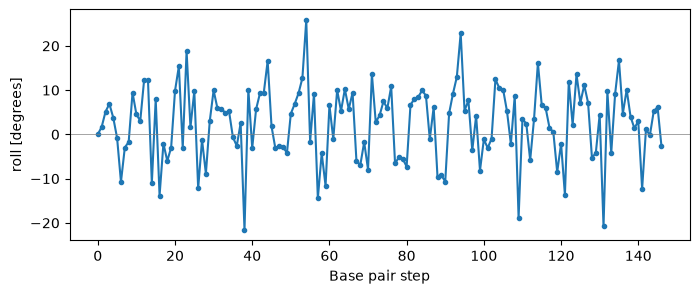

In [5]:
params, names = nucleosome.get_parameters(step=True)
roll = params[0, :, names.index('roll')]

fig, ax = plt.subplots(figsize=[8, 3])
ax.plot(roll, '-o', ms=3)
ax.axhline(0, color='grey', lw=0.5)
ax.set_xlabel('Base pair step')
ax.set_ylabel('roll [degrees]')

Now add 30 bp of linker DNA to each end with `extend()`. The new DNA starts straight and is then minimized with MC. Excluded volume is switched off (`exvol_rad=0`): the wrapped DNA comes close to itself, so the excluded-volume beads would overlap from the start.

In [6]:
nucleosome.extend(n_bp=30, exvol_rad=0)                 # at the 3' end
nucleosome.extend(n_bp=30, exvol_rad=0, forward=False)  # at the 5' end
nucleosome.describe()
view(nucleosome)

Random sequence: TAGAATGCCTTACGGCTGAATGTCCTGAAT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


Random sequence: TAGTACCACTGTAGTCTCCCCAATGTCGTC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


DNA structure with 207 base pairs
Sequence: TAGTACCACTGTAGTCTCCCCAATGTCGTCATCAATATCCACCTGCAGATACTACCAAAAGTGTATTTGGAAACTGCTCCATCAAAAGGCATGTTCAGCTGGAATCCAGCTGAACATGCCTTTTGATGGAGCAGTTTCCAAATACACTTTTGGTAGTATCTGCAGGTGGATATTGATTAGAATGCCTTACGGCTGAATGTCCTGAAT
Trajectory: <mdtraj.Trajectory with 1 frames, 8487 atoms, 414 residues, without unitcells>
Frames:  (207, 1, 4, 3)


<IPython.core.display.Javascript object>

Finally, put the histones back and save the complex:

`view(complex_traj)` shows the complex in 3D, inside the notebook. Drag with the left mouse button to rotate, with the right mouse button to pan, and scroll to zoom. The viewer loads Mol* from the internet, so you need a connection.

In [7]:
histones = pdb.atom_slice(pdb.top.select('protein'))
complex_traj = nucleosome.get_traj().stack(histones)
print(complex_traj)
complex_traj.save_pdb('./nucleosome_with_linkers.pdb')
view(complex_traj)

<mdtraj.Trajectory with 1 frames, 16073 atoms, 1388 residues, without unitcells>


<IPython.core.display.Javascript object>

### Questions

a. The roll goes up and down along the DNA. Estimate the period in base pairs. How is this related to the way the DNA bends around the histones? (Hint: a positive roll bends the DNA towards its major groove.)

b. Compare the mean twist of the nucleosomal DNA with the 34.3 degrees of ideal B-DNA. How many base pairs per turn is that?

c. The linkers have a random sequence. Load the nucleosome again and extend it with a sequence you choose, for example `sequence='A'*30`.

d. Open `nucleosome_with_linkers.pdb` in a viewer. Do the new linkers run into the histones? Check it in code with `md.compute_neighbors()`.

e. MD simulations are often repeated from several different starting structures (replicas). The MC minimization in `extend()` runs at 300 K, so each run gives a different linker conformation. Build three nucleosomes with linkers and save them as separate PDB files. How different are they?

In [8]:
# a. period of the roll, from a Fourier transform (leave out the first step, which is always 0)
spectrum = np.abs(np.fft.rfft(roll[1:] - roll[1:].mean()))
frequencies = np.fft.rfftfreq(len(roll) - 1)
print(f'period of the roll: {1 / frequencies[1:][spectrum[1:].argmax()]:.1f} bp')

period of the roll: 10.4 bp


In [9]:
# b.
twist = params[0, 1:, names.index('twist')]
print(f'mean twist {twist.mean():.1f} degrees, {360 / twist.mean():.2f} bp per turn')

mean twist 34.6 degrees, 10.41 bp per turn


In [10]:
# c.
nucleosome_A = mdna.load(pdb, chainids=[0, 1])
nucleosome_A.extend(sequence='A'*30, exvol_rad=0)
nucleosome_A.describe()

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


DNA structure with 177 base pairs
Sequence: ATCAATATCCACCTGCAGATACTACCAAAAGTGTATTTGGAAACTGCTCCATCAAAAGGCATGTTCAGCTGGAATCCAGCTGAACATGCCTTTTGATGGAGCAGTTTCCAAATACACTTTTGGTAGTATCTGCAGGTGGATATTGATAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA
Trajectory: <mdtraj.Trajectory with 1 frames, 7257 atoms, 354 residues, without unitcells>
Frames:  (177, 1, 4, 3)


In [11]:
# d. histone atoms within 0.2 nm of the linker DNA (the first and last 30 nucleotides of both strands)
n = nucleosome.n_bp
linker = [a.index for a in complex_traj.top.atoms
          if a.residue.chain.index in (0, 1) and (a.residue.index % n < 30 or a.residue.index % n >= n - 30)]
protein = complex_traj.top.select('protein')
close = md.compute_neighbors(complex_traj, 0.2, np.array(linker), haystack_indices=protein)[0]
print(f'{len(close)} histone atoms within 0.2 nm of the linkers')
print(sorted({f'chain {complex_traj.top.atom(i).residue.chain.index} {complex_traj.top.atom(i).residue}' for i in close}))

2 histone atoms within 0.2 nm of the linkers
['chain 4 LYS126']


In [12]:
# e. three starting structures; compare the distance between the two ends of the DNA
for i in range(3):
    replica = mdna.load(pdb, chainids=[0, 1])
    replica.extend(n_bp=30, exvol_rad=0)
    replica.extend(n_bp=30, exvol_rad=0, forward=False)
    replica.get_traj().stack(histones).save_pdb(f'./nucleosome_replica_{i}.pdb')
    ends = replica.get_frames()[[0, -1], -1, 0]
    print(f'replica {i}: the two ends of the DNA are {np.linalg.norm(ends[0] - ends[1]):.1f} nm apart')

Random sequence: GGTAATTCCAAACGCAGGGGCGCGATAATC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


Random sequence: CCACCCGTGGAGTTATACCTCTCCTGACCA 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


replica 0: the two ends of the DNA are 2.1 nm apart


Random sequence: CCGTCGTTTTGGAGCAGAGTCGGCGCGCAA 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


Random sequence: TGGGCTTCGTTCACGAGAAACGGTTTCGGC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


replica 1: the two ends of the DNA are 5.0 nm apart


Random sequence: TCAGCGGGCACTAGGGTATGACGCTTCTAT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


Random sequence: TAGAGAGTGATAGGTGAGCGGAGGGACCGG 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0 
temperature = 300
Circular: False


replica 2: the two ends of the DNA are 4.5 nm apart


**Answers**

a. The roll oscillates with a period of about 10.4 bp, one helical turn. Each turn, the major groove faces the histones once (positive roll, the DNA bends towards the major groove) and the minor groove faces the histones once (negative roll). Adding up these small bends wraps the DNA around the histones.

b. The mean twist is about 34.6 degrees, 10.4 bp per turn: slightly more twisted than ideal B-DNA (10.5 bp per turn).

c. See the code above.

d. Yes, a few atoms. In our runs the new linkers ran into the N-terminal tail of histone H3 (chain 6, residues 14 to 33) and sometimes the C-terminal tail of histone H2A (chain 4). The exact contacts vary, because the linkers are minimized with MC. Histone tails are flexible and stick out of the core of the nucleosome. Before MD, you would move the tails or minimize the whole complex carefully, for example with restraints on the DNA.

e. The distance between the two ends of the DNA differs by several nm between the replicas: each linker is a different thermal conformation at 300 K. Starting replicas from different structures makes them more independent than starting them all from the same structure.

## 2. Connecting DNA

`mdna.connect()` joins the 3' end of one DNA to the 5' end of another DNA, and fills the gap between them with new DNA. It chooses the number of new base pairs so that they fit the gap and their twist matches both ends. Then it relaxes the new DNA with a short MC minimization, while the two original pieces stay in place.

To test it, cut 12 bp out of the middle of a 36 bp DNA and let `connect()` fill the gap. mdna describes a DNA by the reference frames of its base pairs (`get_frames()` in `1_analyze.ipynb`), so you can cut the DNA by taking slices of its frames:

Random sequence: GATAACTGTTCGTTCGGGAATGAAAGAAGGTTCATT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 36

Optimal number of base pairs: 12
Random sequence: TTATTCACCGTG 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


DNA structure with 36 base pairs
Sequence: GATAACTGTTCGTTATTCACCGTGAGAAGGTTCATT
Trajectory: <mdtraj.Trajectory with 1 frames, 1476 atoms, 72 residues, without unitcells>
Frames:  (36, 1, 4, 3)


<IPython.core.display.Javascript object>

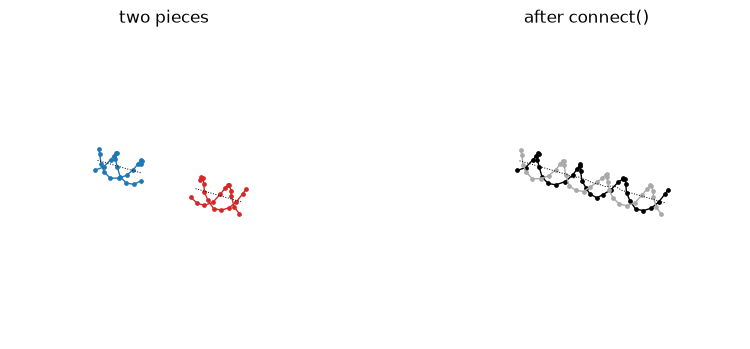

In [13]:
dna = mdna.make(n_bp=36)
frames = dna.get_frames()[:, -1]   # (n_bp, 4, 3): the origin and three axes of each base pair
left = mdna.load(frames=frames[:12], sequence=dna.sequence[:12])
right = mdna.load(frames=frames[24:], sequence=dna.sequence[24:])

joined = mdna.connect(left, right)
joined.describe()

fig = plt.figure(figsize=[10, 4])
ax = fig.add_subplot(121, projection='3d')
left.draw(ax=ax, color_lead='tab:blue', color_anti='tab:blue')
right.draw(ax=ax, color_lead='tab:red', color_anti='tab:red')
ax.set_title('two pieces')
ax = fig.add_subplot(122, projection='3d')
joined.draw(ax=ax)
ax.set_title('after connect()')

view(joined)

The function below prints the mean rise and twist of the new DNA, including the two steps that join it to the original pieces:

In [14]:
def linker_shape(joined, left, right):
    """Mean rise and twist of the base-pair steps that involve the new DNA."""
    params, names = joined.get_parameters(step=True)
    new = params[-1, left.n_bp:joined.n_bp - right.n_bp + 1]
    n_new = joined.n_bp - left.n_bp - right.n_bp
    print(f'{n_new} new base pairs: rise {new[:, names.index("rise")].mean():.2f} Å, twist {new[:, names.index("twist")].mean():.1f} degrees')

linker_shape(joined, left, right)

12 new base pairs: rise 3.38 Å, twist 34.7 degrees


### Questions

a. How many base pairs does `connect()` put in the gap? Compare with the 12 bp you cut out, and compare the rise and twist of the new DNA with those of B-DNA (3.4 Å and 34.3 degrees).

b. Move the right piece 1 nm further away and connect again. The DNA was built along the x axis, so add 1 nm to the x coordinate of its origins: `moved = frames[24:].copy()`, `moved[:, 0] += [1, 0, 0]`, and load it with `mdna.load(frames=moved, sequence=dna.sequence[24:])`. How many base pairs does `connect()` choose now, and what is the rise? Is this a good model? (Hint: the new DNA has to match the twist at both ends, not only the length of the gap.)

c. Choose the number of base pairs yourself, for example `mdna.connect(left, moved_right, n_bp=15)`, and try a few values. How does the new DNA fill the gap now? With `sequence=...` instead of `n_bp` you also choose the sequence of the new DNA.

In [15]:
# a. see the output above

# b.
moved = frames[24:].copy()
moved[:, 0] += [1, 0, 0]
moved_right = mdna.load(frames=moved, sequence=dna.sequence[24:])
joined_moved = mdna.connect(left, moved_right)
linker_shape(joined_moved, left, moved_right)

Optimal number of base pairs: 33
Random sequence: AAACGCGCACATCCTGTAGGGGTTCCCCACTAT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


33 new base pairs: rise 3.19 Å, twist 33.4 degrees


In [16]:
# c.
for n_bp in [12, 13, 14, 15, 16, 17]:
    joined_n = mdna.connect(left, moved_right, n_bp=n_bp)
    linker_shape(joined_n, left, moved_right)

Random sequence: GATACTAGCATC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


12 new base pairs: rise 4.00 Å, twist 35.3 degrees
Random sequence: GCGCCCTAATGCC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


13 new base pairs: rise 3.76 Å, twist 32.0 degrees
Random sequence: ATCCTCAGCACCAT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


14 new base pairs: rise 3.58 Å, twist 31.0 degrees
Random sequence: ACCGGGGATCGTCGT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


15 new base pairs: rise 3.41 Å, twist 28.7 degrees
Random sequence: ACACCCATTACCCCAC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


16 new base pairs: rise 3.24 Å, twist 26.8 degrees
Random sequence: GTAAAAACGAGCATGCG 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


17 new base pairs: rise 3.01 Å, twist 25.4 degrees


**Answers**

a. 12 bp, exactly the number you cut out. The gap is 13 base-pair steps long, and with 12 new base pairs the twist also matches both ends. The rise and twist of the new DNA are close to B-DNA (3.4 Å and 34.3 degrees), but vary from step to step, because the MC minimization runs at 300 K.

b. 33 bp, although about 15 bp would fit the 5.4 nm gap. `connect()` takes the smallest number of base pairs that spans the gap and whose twist matches both ends within 0.65 degrees per step. You moved the right piece without turning it, so the twist no longer fits 15 bp, and the first number that fits is two helical turns later. The 33 bp are squeezed into the gap: in our runs the rise stayed between 1.7 and 2.8 Å after the minimization, which cannot fix this because both ends are held in place. Not a good model: always check the new DNA, or choose the number of base pairs yourself.

c. Fewer base pairs stretch the new DNA, more squeeze it, and the twist changes with the number. With 12 bp the twist is right (about 34 degrees) but the rise is 4.0 Å; with 15 bp the rise is right (3.4 Å) but the DNA is underwound (about 28 degrees). No number fits both, because the right piece moved without turning. A compromise such as 14 or 15 bp is a reasonable start for MD, which relaxes the rest.

### A DNA loop between proteins

Proteins that bind DNA at two places can fold the DNA in between into a loop. Here you use the structure 8SRP, in which FOXP3 proteins form a ladder between two DNA duplexes, and connect the two duplexes into one DNA loop.

In [17]:
# download the structure from the Protein Data Bank (only the first time)
if not os.path.exists('data/8srp.pdb'):
    urllib.request.urlretrieve('https://files.rcsb.org/download/8SRP.pdb', 'data/8srp.pdb')

foxp3 = md.load('data/8srp.pdb')   # mdtraj may warn about the unit cell; you can ignore that
for chain in foxp3.top.chains:
    print(f'chain {chain.index}: {chain.n_residues} residues, first residue {chain.residue(0).name}')

chain 0: 86 residues, first residue ASN
chain 1: 84 residues, first residue MET
chain 2: 54 residues, first residue DA
chain 3: 54 residues, first residue DT
chain 4: 53 residues, first residue DA
chain 5: 53 residues, first residue DT
chain 6: 84 residues, first residue MET
chain 7: 85 residues, first residue MET
chain 8: 84 residues, first residue MET
chain 9: 85 residues, first residue MET
chain 10: 84 residues, first residue MET
chain 11: 86 residues, first residue ASN
chain 12: 84 residues, first residue ASP
chain 13: 87 residues, first residue HIS


/Users/heesch/Projects/MDNA-workshop/.pixi/envs/default/lib/python3.14/site-packages/mdtraj/formats/pdb/pdbfile.py:214: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn(


Chains 2 and 3 form one DNA duplex, chains 4 and 5 the other. Load both, and find the two ends that should be connected: the last base pair of duplex a and the first base pair of duplex b.

In [18]:
dna_a = mdna.load(foxp3, chainids=[2, 3])
dna_b = mdna.load(foxp3, chainids=[4, 5])
protein = foxp3.atom_slice(foxp3.top.select('protein'))

start = dna_a.get_frames()[-1, 0, 0]   # last base pair of duplex a
end = dna_b.get_frames()[0, 0, 0]      # first base pair of duplex b
print(f'distance between the two ends: {np.linalg.norm(end - start):.1f} nm')

distance between the two ends: 5.2 nm


To make a loop instead of a short straight connection, give `connect()` control points that lead the DNA away from the protein: in the direction from the centre of the protein to the middle of the two ends.

Random sequence: GACTCTATATCTAACTTTATACGTTAGACTCTGTTACGCCTCGCCATTATCGGTATCTAGTTTTATATCGAAATAGGGATGAGCTGAAGT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


DNA structure with 197 base pairs
Sequence: AAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAGACTCTATATCTAACTTTATACGTTAGACTCTGTTACGCCTCGCCATTATCGGTATCTAGTTTTATATCGAAATAGGGATGAGCTGAAGTAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACAAACA
Trajectory: <mdtraj.Trajectory with 1 frames, 8077 atoms, 394 residues, without unitcells>
Frames:  (197, 1, 4, 3)


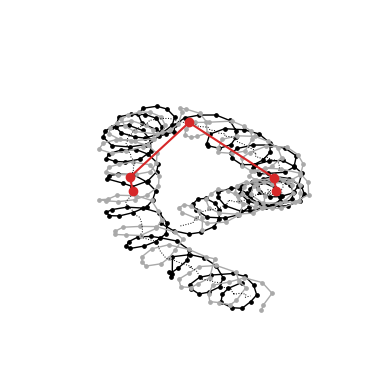

In [19]:
middle = (start + end) / 2
away = middle - protein.xyz[0].mean(axis=0)
away /= np.linalg.norm(away)

height = 15  # how far the loop sticks out, in nm
control_points = np.array([start, start + 3 * away, middle + height * away, end + 3 * away, end])

loop = mdna.connect(dna_a, dna_b, control_points=control_points)
loop.describe()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
loop.draw(ax=ax)
ax.plot(*control_points.T, 'o-', color='tab:red')

In [20]:
complex_loop = protein.stack(loop.get_traj())
complex_loop.save_pdb('./foxp3_dna_loop.pdb')
print(complex_loop)
view(complex_loop)

<mdtraj.Trajectory with 1 frames, 13212 atoms, 1243 residues, without unitcells>


<IPython.core.display.Javascript object>

### Questions

a. How many base pairs are in the loop? Change `height` and see how the size of the loop changes.

b. Connect the two duplexes without control points: `mdna.connect(dna_a, dna_b)`. How many base pairs does the straight connection get, and what are its rise and twist (use `linker_shape()` from above)? Why is a loop an easier way to connect these two duplexes?

c. Count the protein atoms within 0.2 nm of the DNA in `complex_loop`, and find out which nucleotides they touch. Compare with the crystal structure `foxp3`. Where do the close contacts come from?

In [21]:
# a.
for height in [10, 15, 20]:
    control_points = np.array([start, start + 3 * away, middle + height * away, end + 3 * away, end])
    loop_h = mdna.connect(dna_a, dna_b, control_points=control_points)
    print(f'height {height} nm: {loop_h.n_bp - dna_a.n_bp - dna_b.n_bp} bp in the loop\n')

Random sequence: AAACCCTTGCGCTCTGTTTAGCAGAAACCATGTGCGAAGATAGCTTTAAGTAGCCCTTAAGC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


height 10 nm: 62 bp in the loop

Random sequence: ATACCAGCACAGCGTGTATTTTATCCAGACTCTGAAATAGGCAATCAGCGATCGCACATTACACTACGAAAAGCAGGACAAACGATACCC 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


height 15 nm: 90 bp in the loop

Random sequence: TAGCACTGCGGTAAGAACGGCGCTATTCGGTTAATAGGCGGCCTCATGCTTGAGTTCATCAGGACTGGCTTCAAGCCGCCGCTAAACATAGTGTGTCCTAGGACATGGGAAGCTTTGTT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


height 20 nm: 119 bp in the loop



In [22]:
# b.
straight = mdna.connect(dna_a, dna_b)
linker_shape(straight, dna_a, dna_b)

Optimal number of base pairs: 20
Random sequence: CTCTACAGTATACCCATCGT 

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = False 
excluded volume radius = 0.0 
temperature = 300
Circular: False


20 new base pairs: rise 2.96 Å, twist 33.9 degrees


In [23]:
# c.
dna_atoms = np.arange(protein.n_atoms, complex_loop.n_atoms)
protein_atoms = np.arange(protein.n_atoms)
close_protein = md.compute_neighbors(complex_loop, 0.2, dna_atoms, haystack_indices=protein_atoms)[0]
close_dna = md.compute_neighbors(complex_loop, 0.2, protein_atoms, haystack_indices=dna_atoms)[0]
print(f'{len(close_protein)} protein atoms within 0.2 nm of the DNA')
print('nucleotides involved:', sorted({str(complex_loop.top.atom(i).residue) for i in close_dna}))

crystal = md.compute_neighbors(foxp3, 0.2, foxp3.top.select('not protein'), haystack_indices=foxp3.top.select('protein'))[0]
print(f'crystal structure: {len(crystal)} protein atoms within 0.2 nm of the DNA')

12 protein atoms within 0.2 nm of the DNA
nucleotides involved: ['DG26', 'DT24', 'DT25']
crystal structure: 0 protein atoms within 0.2 nm of the DNA


**Answers**

a. With `height = 15` the loop has about 90 bp; in our runs 10 nm gave about 60 bp and 20 nm about 120 bp. With control points, `connect()` takes the number of base pairs from the length of the curve through them. The minimization then spreads any mismatch in twist over the loop.

b. 20 bp. About 15 bp would span the 5.2 nm gap, but their twist does not match both ends; 20 bp is the first number that does. On a straight line they would have a rise of only 2.5 Å, so during the minimization the new DNA stays compressed or bends sideways. With control points you choose the path, the number of base pairs follows from its length, and a loop is long enough to spread any twist mismatch over many base pairs. That is why a loop is the better way to connect these two duplexes.

c. About a dozen protein atoms come within 0.2 nm, and they touch a few nucleotides of the original duplexes, not the new loop. In the crystal structure nothing is that close. mdna rebuilds every nucleotide from ideal templates placed on the base-pair frames, also the nucleotides that were already in the crystal structure, so small overlaps appear where the protein binds. Energy minimization with the force field removes them. Alternatively, keep the crystal coordinates of the bound DNA and use mdna only for the new loop.

## 3. Modifications your force field may not know

mdna can add chemical modifications and non-canonical bases (see the last slides of the lecture). Building them is easy. Simulating them requires force-field parameters for every new residue, so always check which residue names end up in your PDB file.

In [24]:
dna = mdna.make(sequence='GCGCAATTGCGC')
dna.methylate(CpG=True)   # 5-methylcytosine at every CpG site
print([residue.name for residue in dna.get_traj().top.residues])


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

Methylate all C in CpG context, superseeds methylations list.
Methtylating: [1, 9]
['DG', 'DCM', 'DG', 'DC', 'DA', 'DA', 'DT', 'DT', 'DG', 'DCM', 'DG', 'DC', 'DG', 'DC', 'DG', 'DC', 'DA', 'DA', 'DT', 'DT', 'DG', 'DC', 'DG', 'DC']


In a Hoogsteen base pair, the purine is rotated by 180 degrees around its glycosidic bond, so it pairs with a different edge. Flip base pair 5 (an A-T pair) and compare the base-pair parameters with the normal Watson-Crick structure:

In [25]:
watson_crick = mdna.make(sequence='GCGCAATTGCGC')
hoogsteen = mdna.make(sequence='GCGCAATTGCGC')
hoogsteen.flip(fliplist=[5], deg=180)
hoogsteen.save_pdb('./hoogsteen')
view(hoogsteen)

for label, obj in [('Watson-Crick', watson_crick), ('Hoogsteen', hoogsteen)]:
    params, names = obj.get_parameters(base=True)
    print(label, {name: round(float(params[0, 5, i]), 1) for i, name in enumerate(names)})


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

Flipped residues [5] by 3.141592653589793 radians


<IPython.core.display.Javascript object>

Watson-Crick

 {'shear': 0.0, 'stretch': 0.0, 'stagger': 0.0, 'buckle': 0.0, 'propeller': 0.0, 'opening': 0.0}


Hoogsteen {'shear': 3.6, 'stretch': -2.6, 'stagger': 3.9, 'buckle': -96.3, 'propeller': 68.9, 'opening': -135.6}


### Questions

a. Which residue name does mdna use for 5-methylcytosine? Would a standard DNA force field recognise it?

b. Which base-pair parameters change when you flip the base, and why?

c. In a real Hoogsteen base pair the C1' atoms of the two nucleotides are about 0.2 nm closer together than in a Watson-Crick pair. Measure the C1'-C1' distance of base pair 5 in both structures. Does mdna change it?

d. Build a duplex with the fluorescent base 2-aminopurine (`E`), and one with the Hachimoji bases (`B`, `S`, `P`, `Z`). Which residue names do you get?

In [26]:
# a.
print(sorted({residue.name for residue in dna.get_traj().top.residues}))

['DA', 'DC', 'DCM', 'DG', 'DT']


In [27]:
# c.
def c1_distance(obj, bp):
    """Distance (nm) between the C1' atoms of base pair bp."""
    traj = obj.get_traj()
    partner = 2 * obj.n_bp - 1 - bp   # index of the partner nucleotide on the other strand
    a = traj.top.select(f"resid {bp} and name \"C1'\"")[0]
    b = traj.top.select(f"resid {partner} and name \"C1'\"")[0]
    return md.compute_distances(traj, [[a, b]])[0, 0]

print(f"C1'-C1': Watson-Crick {c1_distance(watson_crick, 5):.2f} nm, Hoogsteen {c1_distance(hoogsteen, 5):.2f} nm")

C1'-C1': Watson-Crick 1.08 nm, Hoogsteen 1.08 nm


In [28]:
# d.
for sequence in ['GCGAEAGCG', 'GCBSPZGC']:
    obj = mdna.make(sequence=sequence)
    print(sequence, sorted({residue.name for residue in obj.get_traj().top.residues}))


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 9

GCGAEAGCG ['DA', 'DC', 'DE', 'DG', 'DT']

Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 8

GCBSPZGC ['DB', 'DC', 'DG', 'DP', 'DS', 'DZ']


**Answers**

a. `DCM`. Standard nucleic-acid force fields contain parameters for A, C, G and T (and U for RNA) only. Parameters for 5-methylcytosine have been published for the common force fields, but you usually have to add them yourself.

b. Opening changes by 180 degrees, because the base is rotated half a turn and its reference frame rotates with it. Shear and stretch change too (to about 4.8 and -3.4 Å), because the reference point of the flipped base moves. The other parameters stay the same, since only one base moves.

c. mdna only rotates the base: the C1'-C1' distance stays at 1.08 nm in both structures. In a real Hoogsteen pair the backbones come closer. In a simulation setup the structure has to relax into this geometry during minimization and equilibration, possibly with restraints that keep the Hoogsteen hydrogen bonds intact.

d. 2-aminopurine is `DE`. The Hachimoji bases are `DB`, `DS`, `DP` and `DZ`. None of these are in standard force fields.

## 4. Supercoiled minicircles

In `2_build.ipynb` you saw that minimizing an overwound minicircle turns part of the extra twist into writhe, while Lk = Tw + Wr stays the same. Here you measure how this depends on the amount of overwinding. Each minimization takes about a minute, so the next cell runs for about 5 minutes.

In [29]:
dLk_values = [0, 4, 8, 12]
results = []
for dLk in dLk_values:
    circle = mdna.make(n_bp=200, circular=True, dLk=dLk)
    circle.minimize(equilibrate_writhe=True)
    circle.save_pdb(f'./minicircle_200bp_dLk{dLk}')
    results.append(circle.get_linking_number())   # [Lk, Wr, Tw]
results = np.array(results)

Random sequence: GCCACACTACTCCGATTTGTCAATCCTTATACGTCTGATGTGAGAACAGACAAATGCCCATGGCTTGTGAGCTAGAGCGAAAGAATGCTGGCCTTAAAATTACAAGTTAGTGGGCCAGGTGTATCATTCCGAAAGTCAACTCAGTTCTATCGATTCGATGATTTTATAAGTTGGTAGGGCATTCATGACCTCATCCGTTT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

Adjusting twist to match ΔLk = 0
	Current twist number (Tw₀): 19.00
	Computed writhe (Wr):        0.00
	Target twist number (Tw):    19.00
	Resulting Lk = Tw + Wr:      19.00
	Old twist angle per bp:      34.20°
	New twist angle per bp:      34.20°

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = True 
excluded volume radius = 2.0 
temperature = 300
Circular: True


####################################
Initiating Excluded Volume...
EV_bead mismatch: including additional boundary checks.

######################################
#### INITIALIZING EXCLUDED VOLUME ####
######################################
 Excluded Volume Beads: 
   number of EV beads: 29
   bp per EV bead:     7
   Effective size:     3.57
   Exclusion distance: 4.0
######################################


E1 = 552.35 kT
E2 = 618.47 kT
wr_equi=False
wr1 = -0.07
wr2 = -0.01


E = 594.84 kT
E_num_below=1
wr = -0.05
wr_num_below=1


E = 605.72 kT
E_num_below=2
wr = 0.01
wr_num_below=0


E = 606.83 kT
E_num_below=3
wr = 0.03
wr_num_below=0


... (35 outputs left out)

E = 2022.56 kT
E_num_below=0
wr = 3.00
wr_num_below=0


E = 2030.27 kT
E_num_below=1
wr = 2.87
wr_num_below=1


E = 2053.80 kT
E_num_below=2
wr = 2.80
wr_num_below=2


E = 2037.58 kT
E_num_below=3
wr = 2.82
wr_num_below=3


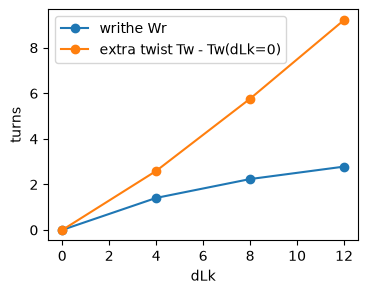

In [30]:
fig, ax = plt.subplots(figsize=[4, 3])
ax.plot(dLk_values, results[:, 1], 'o-', label='writhe Wr')
ax.plot(dLk_values, results[:, 2] - results[0, 2], 'o-', label='extra twist Tw - Tw(dLk=0)')
ax.set_xlabel('dLk')
ax.set_ylabel('turns')
ax.legend()

In [31]:
# The saved minicircles, from relaxed (dLk = 0) to strongly overwound (dLk = 12)
for dLk in dLk_values:
    view(md.load(f'./minicircle_200bp_dLk{dLk}.pdb'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### From the coarse-grained model back to atoms

`minimize()` runs a Monte Carlo simulation of a coarse-grained model, in which every base pair is a rigid body. It keeps snapshots of this simulation, and mdna can build an atomistic structure for each of them. This is called backmapping. Use it to make an atomistic movie of how the last minicircle (dLk = 12) supercoils. The same approach gives you several different starting structures for MD replicas.

The snapshots are stored in `circle.minimizer.out`, an internal part of mdna that may change in future versions.

In [32]:
confs = circle.minimizer.out['confs']   # (n_snapshots, n_bp, 4, 4): position and orientation of each base pair
print(confs.shape)

def snapshot_frames(conf):
    """Convert one MC snapshot to mdna reference frames: an origin and three axes per base pair."""
    frames = np.empty((conf.shape[0], 4, 3))
    frames[:, 0] = conf[:, :3, 3]
    frames[:, 1:] = conf[:, :3, :3].transpose(0, 2, 1)
    return frames

snapshots = []
for k in np.linspace(0, len(confs) - 1, 10).astype(int):
    snapshot = mdna.load(frames=snapshot_frames(confs[k]), sequence=circle.sequence, circular=True)
    snapshots.append(snapshot.get_traj())
    print(f'snapshot {k}: [Lk, Wr, Tw] =', np.round(snapshot.get_linking_number(), 2))

movie = md.join(snapshots)
movie[0].save_pdb('./supercoiling_movie.pdb')
movie.save_xtc('./supercoiling_movie.xtc')
print(movie)
view(movie)

(901, 200, 4, 4)
snapshot 0: [Lk, Wr, Tw] = [31.  0. 31.]


snapshot 100: [Lk, Wr, Tw] = [31.    2.55 28.45]
snapshot 200: [Lk, Wr, Tw] = [31.    2.84 28.16]


snapshot 300: [Lk, Wr, Tw] = [31.    2.79 28.21]
snapshot 400: [Lk, Wr, Tw] = [31.    2.86 28.14]


snapshot 500: [Lk, Wr, Tw] = [31.    2.87 28.13]
snapshot 600: [Lk, Wr, Tw] = [31.    3.03 27.97]


snapshot 700: [Lk, Wr, Tw] = [31.    3.02 27.98]


snapshot 800: [Lk, Wr, Tw] = [31.   2.8 28.2]
snapshot 900: [Lk, Wr, Tw] = [31.    2.78 28.22]


<mdtraj.Trajectory with 10 frames, 8200 atoms, 400 residues, without unitcells>


<IPython.core.display.Javascript object>

### Questions

a. What fraction of the extra linking number ends up as writhe? Is that fraction the same for each dLk?

b. Look at the saved minicircles in a viewer. From which dLk does the minicircle clearly bend out of its plane?

c. Supercoiling is often given as the superhelical density σ = dLk / Lk0, with Lk0 = n_bp / 10.5 the linking number of relaxed DNA. Bacterial plasmids have σ ≈ -0.06. Which dLk is that for a 200 bp minicircle? Compare it with the values used here.

d. Repeat the experiment with negative dLk (underwound DNA, as in most cells). Does the DNA respond in the same way?

e. Play the movie above (or load `supercoiling_movie.pdb` together with `supercoiling_movie.xtc` in a viewer). How does the shape change, and how does that match the printed writhe?

In [33]:
# a.
for dLk, (lk, wr, tw) in zip(dLk_values, results):
    if dLk != 0:
        print(f'dLk = {dLk:2d}: Wr = {wr:.2f}, so {100 * wr / dLk:.0f}% of dLk went into writhe')

dLk =  4: Wr = 1.41, so 35% of dLk went into writhe
dLk =  8: Wr = 2.24, so 28% of dLk went into writhe
dLk = 12: Wr = 2.78, so 23% of dLk went into writhe


In [34]:
# c.
lk0 = 200 / 10.5
print(f'Lk0 = {lk0:.2f}; sigma = -0.06 means dLk = {-0.06 * lk0:.1f}')
print('sigma of the values used here:', np.round(np.array(dLk_values) / lk0, 2))

Lk0 = 19.05; sigma = -0.06 means dLk = -1.1
sigma of the values used here: [0.   0.21 0.42 0.63]


In [35]:
# d. (takes about 2 minutes)
for dLk in [-4, -8]:
    circle = mdna.make(n_bp=200, circular=True, dLk=dLk)
    circle.minimize(equilibrate_writhe=True)
    print(f'dLk = {dLk}: [Lk, Wr, Tw] =', np.round(circle.get_linking_number(), 2))

Random sequence: CACGTAGTCTCTACAGCGGATGCACTTACCGAAGCAGTGTTAATGCGCCCCTTTGTGTCTATTGACAGAGGCTAACCGGGTGAAAGCGAGCGCAGATAACACTCCTTAGACGGGGACGGCTTAAAGTCAAAACGTGGACGGTGAGAGACCGTGCGAGTATTATCAATATTCTTAGTCAAAGGAATGCACGAATACATCTT 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

Adjusting twist to match ΔLk = -4
	Current twist number (Tw₀): 19.00
	Computed writhe (Wr):        0.00
	Target twist number (Tw):    15.00
	Resulting Lk = Tw + Wr:      15.00
	Old twist angle per bp:      34.20°
	New twist angle per bp:      27.00°

Minimize the DNA structure:
simple equilibration = False 
equilibrate writhe = True 
excluded volume radius = 2.0 
temperature = 300
Circular: True
##########################

E1 = 799.87 kT
E2 = 791.82 kT
wr_equi=False
wr1 = 0.13
wr2 = -0.25


E = 792.52 kT
E_num_below=1
wr = -0.67
wr_num_below=0


E = 766.66 kT
E_num_below=0
wr = -0.71
wr_num_below=0


E = 754.47 kT
E_num_below=0
wr = -0.81
wr_num_below=0


E = 733.50 kT
E_num_below=0
wr = -0.92
wr_num_below=0


... (13 outputs left out)

E = 1210.38 kT
E_num_below=0
wr = -1.17
wr_num_below=2


E = 1254.54 kT
E_num_below=1
wr = -1.10
wr_num_below=3


E = 1226.87 kT
E_num_below=2


E = 1215.32 kT
E_num_below=3
dLk = -8: [Lk, Wr, Tw] = [11.   -1.32 12.32]


**Answers** (the exact numbers vary between runs)

a. Roughly 20 to 40%, and less for larger dLk; the rest stays as twist. The exact numbers vary between runs, because the minimization runs at 300 K. Writhe grows with dLk, but more slowly than dLk itself.

b. At dLk = 0 the circle stays roughly flat. At dLk = 4 it already bends clearly out of its plane. At larger dLk the DNA winds further around itself, so the writhe keeps growing.

c. Lk0 = 19.05, so σ = -0.06 is dLk ≈ -1.1. The values used here are σ = 0.2 to 0.6, far beyond what cells reach. A 200 bp circle is short and stiff: bending it into a supercoil costs a lot of energy, so it only writhes when it is strongly overwound. Plasmids of thousands of base pairs writhe at much smaller σ.

d. Wr becomes negative, with about the same size as for the same positive dLk (compare with the output of question a; the numbers vary between runs). In this elastic model the response is roughly symmetric. Real DNA responds differently to underwinding than to overwinding: it can open base pairs or form other structures, which an elastic model of rigid base pairs cannot describe.

e. The movie starts from the flat, overwound circle (Wr = 0). Early in the simulation the circle bends out of its plane and the writhe jumps to about 3; after that it only fluctuates. The linking number stays the same in every frame.

## 5. Interlocked DNA rings

Some organisms keep DNA as interlocked rings. In trypanosomes, the parasites that cause sleeping sickness, the mitochondrial DNA (kinetoplast DNA) is a network of thousands of small DNA circles, linked together like chain mail. Two linked rings cannot be separated without cutting one of them, even though no bond connects them.

How strongly two closed curves are linked is measured by their linking number, computed with Gauss's linking integral. This is the same quantity as the linking number Lk between the two strands of a minicircle.

In [36]:
def ring(radius, center, plane):
    """Control points of a circle in the 'xy', 'xz' or 'yz' plane. The first and last point are the same."""
    t = np.linspace(0, 2 * np.pi, 60)
    a, b, zero = radius * np.cos(t), radius * np.sin(t), np.zeros_like(t)
    points = {'xy': [a, b, zero], 'xz': [a, zero, b], 'yz': [zero, a, b]}[plane]
    return np.array(points).T + np.array(center)

def linking_number(curve1, curve2):
    """Gauss linking number of two closed curves, each an (n, 3) array whose first and last point are the same."""
    d1, d2 = np.diff(curve1, axis=0), np.diff(curve2, axis=0)   # short segments along each curve
    m1, m2 = curve1[:-1] + d1 / 2, curve2[:-1] + d2 / 2         # midpoints of the segments
    r = m1[:, None, :] - m2[None, :, :]
    cross = np.cross(d1[:, None, :], d2[None, :, :])
    integrand = np.einsum('ijk,ijk->ij', r, cross) / np.linalg.norm(r, axis=-1)**3
    return integrand.sum() / (4 * np.pi)

linking number of the two curves: -1.0
Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.74 degrees
	New twist angle per base pair: 35.03 

Random sequence: GGGTCACGCCTAACTCGAGCCTCATTCACATAGACACTAAATACCGTGTGGCAAGGCAAGCATAAAGCGCCCTGACGGGTCCAATACTTTTCTAGTTCTGCTTAAAGGAGCGTGGCAAGACAAACTCGGTCAGTCTTATAGTCGCTTATTTGTATTGTTTGAGCGGCCTCGGGCTCAGCATACGA 

Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.74 degrees
	New twist angle per base pair: 35.03 

Random sequence: CCCGGATCGCACTCGACATGCTTGTGACATGGCTGCATGGCCATTGTCCCGCAGTTCAAAGACTTGCCCTCATGAAACTGCTGGGCCGTCTGGAGTGTCCGTGATGGACTTACAAGTTGGACAACTACTTGCCCACGGCGAACACGGTCTATCAACATGACATCACTTGGCCAGGTCTGGACAAG 



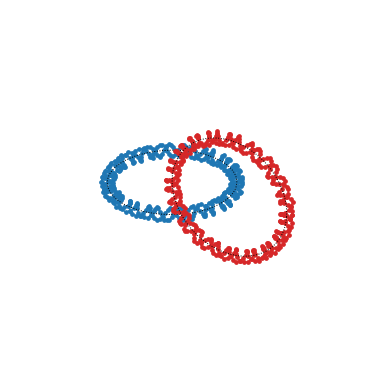

In [37]:
radius = 10  # nm
points1 = ring(radius, center=[0, 0, 0], plane='xy')
points2 = ring(radius, center=[radius, 0, 0], plane='xz')   # passes through the hole of ring 1
print('linking number of the two curves:', round(linking_number(points1, points2), 2))

ring1 = mdna.make(control_points=points1, circular=True)
ring2 = mdna.make(control_points=points2, circular=True)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ring1.draw(ax=ax, color_lead='tab:blue', color_anti='tab:blue')
ring2.draw(ax=ax, color_lead='tab:red', color_anti='tab:red')

The linking number of the DNA itself follows from the helix axes, the curves through the base-pair centres. Save both rings in one PDB file to look at them in a viewer:

In [38]:
def axis(dna):
    """Closed curve through the base-pair centres of a circular DNA."""
    origins = dna.get_frames()[:, -1, 0]
    return np.vstack([origins, origins[:1]])

print('linking number of the two DNA rings:', round(linking_number(axis(ring1), axis(ring2)), 2))

catenane = ring1.get_traj().stack(ring2.get_traj())
catenane.save_pdb('./catenane.pdb')
print(catenane)
view(catenane)

linking number of the two DNA rings: -1.0
<mdtraj.Trajectory with 1 frames, 15170 atoms, 740 residues, without unitcells>


<IPython.core.display.Javascript object>

### Questions

a. Move ring 2 so that it no longer passes through ring 1, for example `center=[2.5 * radius, 0, 0]`. What is the linking number now?

b. What happens to the sign of the linking number when you reverse the direction of one ring (`points2[::-1]`)?

c. Build a chain of five rings, each linked to the next, and save it as one PDB file. Compute the linking number of every pair of rings: which pairs are linked? (Hint: place the centres 1.5 radius apart along x and alternate between the 'xy' and 'xz' planes.)

d. Thinking question: the enzyme topoisomerase II separates linked rings. It cuts both strands of one ring, passes the other ring through the gap and seals the cut. By how much does the linking number between the two rings change in one such step?

In [39]:
# a.
points_far = ring(radius, center=[2.5 * radius, 0, 0], plane='xz')
print('a. moved ring:', round(linking_number(points1, points_far), 2))

# b.
print('b. reversed ring:', round(linking_number(points1, points2[::-1]), 2))

a. moved ring: -0.0
b. reversed ring: 1.0


In [40]:
# c.
chain_points = [ring(radius, center=[1.5 * i * radius, 0, 0], plane='xy' if i % 2 == 0 else 'xz') for i in range(5)]
chain_rings = [mdna.make(control_points=points, circular=True) for points in chain_points]

chain_traj = chain_rings[0].get_traj()
for r in chain_rings[1:]:
    chain_traj = chain_traj.stack(r.get_traj())
chain_traj.save_pdb('./ring_chain.pdb')

lk = np.array([[linking_number(p, q) if i != j else 0 for j, q in enumerate(chain_points)] for i, p in enumerate(chain_points)])
print(np.round(lk).astype(int))

Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.74 degrees
	New twist angle per base pair: 35.03 

Random sequence: TGCCCCAGCAAGAACATTTATCCCAATATACGGTACGTCCCCTTCTCACGACCATCTCTTTATCAATGATTGAGCCTCTCTGTGCGGCTTCGGTGCGGCGAACGCCACGGCCAAACGACAAAAACATAGGTAATGAGATGTATCCACAGCGGAAGGGCTCCAATACCAACGTATATCGCTACTTC 

Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.74 degrees
	New twist angle per base pair: 35.03 

Random sequence: TATGTGGGGAATTATGTGGACCCAACTTTCATCCACATACACCTTGTACAGATTCGCGTCGGTACTTGCGCTAAGGGCACATATCCGCACGCAACACCGTAAACAAGAGTCTGTGCGCGCCGACAAATAAGTGCACTCTAACTCATCCTGCCGTTGACGCTGGGAGTAGGTAGGCCTCGCTGGTG 

Structure is requested to be circular:
	Excess twist per base to make ends meet: 0.74 degrees
	New twist angle per base pair: 35.03 

Random sequence: CTTGTGCAAGCTGCAGTCATCTCTGTTAAACCGAATGTGAAGAGCTTAGATTAAGCACGCTAAAAACAGTGTACTAAACGGAACGGTCTATCATGAACTTATTCTAGGGAACAAGATAGCAAGTGGTTAGCATTGGCTTTTCGCACTATAGCGTGGAGGAAATGCATTATA

[[ 0 -1  0  0  0]
 [-1  0  1  0  0]
 [ 0  1  0 -1  0]
 [ 0  0 -1  0  1]
 [ 0  0  0  1  0]]


**Answers**

a. 0: the rings are no longer linked.

b. The linking number changes sign, from -1 to +1. The sign depends on the direction of the curves. For DNA, the direction is the 5' to 3' direction of the strands.

c. Each ring is linked to its neighbours (linking number +1 or -1) and not to the other rings (0).

d. By 1. Look at the two rings from one direction and count the points where one ring crosses over the other: the linking number is half the sum of the signs (+1 or -1) of these crossings. Passing one ring through the other turns one crossing into its mirror image, which changes the sum by 2 and the linking number by 1. (Within a single circular DNA, topoisomerase II changes Lk by 2 per step, because it passes a double strand through a double strand.)

## 6. Before you simulate

The energy minimization of your MD engine repairs small errors in a model, for example bonds that are slightly too long where mdna joins its nucleotide templates. Some things it cannot fix, and some you have to sort out before the MD engine even accepts the structure.

### Terminal phosphates

`save_pdb()` writes a phosphate group at the 5' end of each strand. The 5' terminal nucleotides of AMBER force fields have no phosphate, so for example `gmx pdb2gmx` stops with an error. `mdna.sequence_to_pdb(sequence='CGCGAATTCGCG', filename='my_dna', output='GROMACS')` writes a linear DNA without them. The function below does the same for any linear mdna structure:

In [41]:
def save_without_5prime_phosphates(dna, filename):
    """Save a linear DNA without the phosphate group at the 5' end of each strand."""
    traj = dna.get_traj()
    first_residues = [chain.residue(0) for chain in traj.top.chains]   # each strand starts at its 5' end
    remove = {atom.index for residue in first_residues for atom in residue.atoms if atom.name in ('P', 'OP1', 'OP2')}
    keep = [atom.index for atom in traj.top.atoms if atom.index not in remove]
    traj.atom_slice(keep).save_pdb(filename)

dna = mdna.make(sequence='CGCGAATTCGCG')
save_without_5prime_phosphates(dna, './drew_dickerson_amber.pdb')
print('first atoms of strand 1:', [atom.name for atom in md.load('./drew_dickerson_amber.pdb').top.residue(0).atoms][:4])


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

first atoms of strand 1: ["O5'", "C5'", "C4'", "O4'"]


### Overlapping DNA

In a knot, distant parts of the DNA come close to each other. DNA is about 2 nm wide, so the helix axes of two parts of the molecule should stay more than 2 nm apart. An energy minimization cannot pull DNA strands that pass through each other apart again. The function below finds the closest approach between base pairs that are at least 20 base pairs apart along the chain:

In [42]:
def closest_approach(dna, min_separation=20):
    """Smallest distance (nm) between base-pair centres that are at least min_separation base pairs apart."""
    origins = dna.get_frames()[:, -1, 0]
    n = len(origins)
    distances = np.linalg.norm(origins[:, None] - origins[None, :], axis=-1)
    i, j = np.indices(distances.shape)
    separation = np.abs(i - j)
    if dna.circular:
        separation = np.minimum(separation, n - separation)
    return distances[separation >= min_separation].min()

def parametric_trefoil(t, scaling=5):
    x = scaling*(np.sin(t)) + scaling*(2*np.sin(2*t))
    y = scaling*(np.cos(t)) - scaling*(2*np.cos(2*t))
    z = scaling*(-np.sin(3*t))
    return x, y, z

t = np.linspace(0, 2 * np.pi, 50)
knot = mdna.make(control_points=np.array(parametric_trefoil(t, scaling=5)).T, circular=True)
print(f'{knot.n_bp} bp, closest approach {closest_approach(knot):.2f} nm')

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.24 degrees
	New twist angle per base pair: 34.04 

Random sequence: GTGATCAATTCCTACACAGTATTGGAGTCACTGCTATTAACATTGAATACGCGTCTGGGCCGCACCACTTTGTCTTAATGCATGTATTACGCGCCTCGCATTGAGTGGCCCGCTTAGATTATGAGCTACCACGCCAGAGCCAAATGCATCAATTGAGGACTACTTCACGCGCCTGAGCAGCGAACGAGAGGCAACGTGCCGAAAGCGGAACATCTGATAACCCCGAGATCAATTGACTATAGAACATGTGACGATGTACTGCGGAAGGGCGTACCTGGATCTGGACCCAAAATATGCTTGGCGGGTGGCTGCATAGTCTGCTCACCCGCTTGCATCAAAACTGTCCCCGCAGAATATACTATAGTGCTGGAGTATAAGGAATAGGCAACCTCTAACTGGCAAATCTCAAAATAGTTACCAACT 

423 bp, closest approach 6.07 nm


### How big will the system be?

In an MD simulation the DNA sits in a box of water, usually with at least 1 nm of water between the DNA and the edge of the box. The function below estimates the size of a cubic box, the number of water molecules (about 33 per nm³) and the number of sodium ions that make the system neutral (one per phosphate).

In [43]:
def system_size(dna, padding=1.0):
    """Rough size of the DNA in a cubic water box with `padding` nm of water on every side."""
    traj = dna.get_traj()
    xyz = traj.xyz[-1]
    box = (xyz.max(axis=0) - xyz.min(axis=0)).max() + 2 * padding  # edge of the box in nm
    waters = int(33.4 * box**3)
    ions = len(traj.top.select('name P'))
    dna_atoms = int(1.6 * traj.n_atoms)  # mdna writes no hydrogens; adding them gives about 60% more atoms
    total = dna_atoms + 3 * waters + ions
    print(f'{dna.n_bp} bp: box {box:.1f} nm, {waters:,} waters, {ions} Na+, about {total:,} atoms')

system_size(mdna.make(sequence='CGCGAATTCGCG'))


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 12

12 bp: box 6.0 nm, 7,364 waters, 24 Na+, about 22,903 atoms


### Questions

a. Why should you not use `save_without_5prime_phosphates()` for a circular DNA?

b. Make the trefoil smaller by lowering `scaling`. Below which value do parts of the knot overlap?

c. Compare the system size of a straight 200 bp DNA (`mdna.make(n_bp=200)`) with a 200 bp minicircle (`mdna.make(n_bp=200, circular=True)`). Why do the numbers differ so much? How could you simulate a long linear DNA anyway?

In [44]:
# b.
for scaling in [3, 2, 1.5]:
    knot = mdna.make(control_points=np.array(parametric_trefoil(t, scaling=scaling)).T, circular=True)
    print(f'scaling {scaling}: {knot.n_bp} bp, closest approach {closest_approach(knot):.2f} nm')

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.27 degrees
	New twist angle per base pair: 34.02 

Random sequence: TGCCGGGGGGTATTACGACGTAAATTTCCGATAGGACACTTAAGAAACTTGGAGCGGAGGGGCCCAGACTCTGAATTACATGTTCATATAACTTGTCGCGGCCATAGCTCATGGCTGGACAAGCCCCCCTTGCTAGCCACAGCTGCAACTTGGCTTCAACCTATCTTATCACCTATGTGACGATATAAGGCAAGCTTCGTAAATCTGCAGAGTGCGAACGTTGACGTATGTTCTAACAGTGTCGTTCTTCTTCG 

scaling 3: 254 bp, closest approach 3.64 nm
Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.20 degrees
	New twist angle per base pair: 34.08 

Random sequence: AAATGACCCACCAGCTAATAGAGTATAACTTAGACCGTGGTGGCAGAATCGATGACCGACAAATCGCTCAGATTAATGTTCTACGGGGTTGGGGTTAGCCAACATTCCATCGATCAGTCATTCAGAGACGTATGGTGCGAAATCAAGCGGAGTCAGCTCTGACATGAGT 

scaling 2: 169 bp, closest approach 2.43 nm
Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.27 degrees
	New twist angle per base pair: 34.02 



Random sequence: CGGGTATATGTTTTTATGGCCCGAGCTATGCGACGTCTGAATTAAACCAACTGAACCGTATCTGTATACTCGCCGGTACCCGGTACAAGTACGGCCTCCGAGCCGGCTCCGTTCATTCATGGGGCGG 



scaling 1.5: 127 bp, closest approach 1.82 nm


In [45]:
# c.
system_size(mdna.make(n_bp=200))
system_size(mdna.make(n_bp=200, circular=True))

Random sequence: GTCATAATAGACTGATGAAATATAAAACAAGTTATGAGGCGAGGCCTAGTCAGGGGTGGGGGCACCGACCAGAGACTGCTAGCGTCCGTTGCTGTAGGCTAGGGGTCATGCGCATACCTGGCAACCTACTGTCCCATCCGTTCACATGACCTCGCGCCTGGTACCTTAGGGCTGCGGGCCCTTAGCACTTATACACTTGG 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200



200 bp: box 70.1 nm, 11,521,149 waters, 400 Na+, about 34,576,967 atoms
Random sequence: GCCTCACAGTAACTAGCAACAAGCTGTCCCTTATAGATCTGACGGAGTTGGATTCACCGTGAACAGGGAAGTCTGCTACGCGTCCACACGCAAACGCCTATATGCCAGGCAAAGGCGGGGGCGATACAAAGGCCCATTGGTTACTGCGAATGCATACATTCGCCTACGCTTGGAGGTAGCGCCTGTGATAGACAGACCAC 


Start rescaling spline based on requested number of base pairs.
	This requires recomputation of the control points to match the desired number of base pairs.
	Spline scaled to match the target number of base pairs: 200

Structure is requested to be circular:
	Excess twist per base to make ends meet: -0.09 degrees
	New twist angle per base pair: 34.2 

200 bp: box 25.8 nm, 572,905 waters, 400 Na+, about 1,732,235 atoms


**Answers**

a. A circular DNA has no 5' ends: the phosphate of the first nucleotide connects it to the last nucleotide of the strand. Removing it would cut the circle open.

b. At `scaling=2` the closest approach is about 2.4 nm, at `scaling=1.5` about 1.8 nm. Below roughly 1.7 the DNA overlaps itself.

c. The straight 200 bp DNA is 68 nm long, so a cubic box around it is 70 nm wide: about 11 million waters and 35 million atoms. The minicircle fits in a 26 nm box: about 0.6 million waters and 1.7 million atoms, 20 times fewer. For long linear DNA you can use a rectangular box with the DNA along its long axis, or connect the DNA to its own periodic copy through the wall of the box, which models an infinitely long DNA.

## More to explore

The [mdna documentation](https://heezch.github.io/mdna/) has more tutorials, for example building DNA along a protein filament.